In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os
import re
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler
import plotly.express as px
import matplotlib as mpl

# Initial Device Exploration

In [2]:
# =========================
# CONFIG
# =========================

diretorio = "/Users/luismartins/Desktop/Tese/Tese_repository/Data/"

activation_files = {
    7: "activations_Glass_Washer.csv",
    8: "activations_Dish_Washer_Original.csv",
}

device_names = {
    7: "Glass Washer",
    8: "Dish Washer",
}


# =========================
# AUXILIARY FUNCTIONS
# =========================

def minute_of_day(ts):
    m = ts.hour * 60 + ts.minute
    if ts.second >= 30:
        m += 1
    return min(m, 1439)


def get_time_zone(minute):
    if 0 <= minute <= 599:
        return 0
    elif 600 <= minute <= 1169:
        return 1
    elif 1170 <= minute <= 1349:
        return 2
    else:
        return 3


def load_activation_csv_full_dataset(diretorio, nome_do_arquivo):
    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)

    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_csv(caminho_arquivo, sep=";").iloc[:, 0:3].copy()

    df.columns = df.columns.str.strip()

    df["first_min_on"] = pd.to_datetime(
        df["first_min_on"],
        utc=True,
        errors="coerce"
    )

    df["last_min_on"] = pd.to_datetime(
        df["last_min_on"],
        utc=True,
        errors="coerce"
    )

    df["first_min_on"] = df["first_min_on"].dt.tz_convert(None)
    df["last_min_on"] = df["last_min_on"].dt.tz_convert(None)

    df = df.dropna(subset=["first_min_on", "last_min_on"])
    df = df.sort_values("first_min_on").reset_index(drop=True)

    return df


def extract_device_activations_full_dataset(
    device_idx,
    activation_files,
    diretorio,
    device_names=None
):
    nome_do_arquivo = activation_files[device_idx]

    df = load_activation_csv_full_dataset(
        diretorio=diretorio,
        nome_do_arquivo=nome_do_arquivo
    )

    device_name = (
        device_names.get(device_idx, f"Device {device_idx}")
        if device_names is not None
        else f"Device {device_idx}"
    )

    activations = []

    for activation_id, row in df.iterrows():

        start_ts = row["first_min_on"]
        finish_ts = row["last_min_on"]

        start_minute = minute_of_day(start_ts)
        finish_minute = minute_of_day(finish_ts)

        # duração real em minutos, usando timestamps
        duration = (finish_ts - start_ts).total_seconds() / 60.0

        # incluir ambos os extremos como fazias no X_day
        duration_inclusive = int(round(duration)) + 1

        if duration_inclusive <= 0:
            continue

        activations.append({
            "device": int(device_idx),
            "device_name": device_name,
            "activation_id": int(activation_id),

            "start_datetime": start_ts,
            "finish_datetime": finish_ts,

            "date": start_ts.date(),
            "weekday": start_ts.weekday(),

            "start_hour": int(start_ts.hour),
            "start_minute_clock": int(start_ts.minute),
            "start_minute_of_day": int(start_minute),

            "finish_hour": int(finish_ts.hour),
            "finish_minute_clock": int(finish_ts.minute),
            "finish_minute_of_day": int(finish_minute),

            "time_zone": int(get_time_zone(start_minute)),

            "duration_min": int(duration_inclusive),
        })

    activations_df = pd.DataFrame(activations)

    return activations_df

In [19]:
# Escolhe o device aqui:
#device_idx = 7  # Glass Washer
device_idx = 8 # Dish Washer

activations_df = extract_device_activations_full_dataset(
    device_idx=device_idx,
    activation_files=activation_files,
    diretorio=diretorio,
    device_names=device_names
)

print(activations_df.head())
print(activations_df.tail())
print(activations_df.shape)

   device  device_name  activation_id      start_datetime     finish_datetime  \
0       8  Dish Washer              0 2019-02-13 13:35:00 2019-02-13 13:36:00   
1       8  Dish Washer              1 2019-02-13 13:47:30 2019-02-13 13:58:30   
2       8  Dish Washer              2 2019-02-13 14:01:30 2019-02-13 14:03:00   
3       8  Dish Washer              3 2019-02-13 14:16:30 2019-02-13 14:17:30   
4       8  Dish Washer              4 2019-02-13 14:29:00 2019-02-13 14:45:30   

         date  weekday  start_hour  start_minute_clock  start_minute_of_day  \
0  2019-02-13        2          13                  35                  815   
1  2019-02-13        2          13                  47                  828   
2  2019-02-13        2          14                   1                  842   
3  2019-02-13        2          14                  16                  857   
4  2019-02-13        2          14                  29                  869   

   finish_hour  finish_minute_clock  f

In [20]:
cols_to_show = [
    "device_name",
    "activation_id",
    "date",
    "weekday",
    "start_hour",
    "start_minute_clock",
    "finish_hour",
    "finish_minute_clock",
    "start_minute_of_day",
    "finish_minute_of_day",
    "time_zone",
    "duration_min"
]

print(activations_df[cols_to_show].head(30))

    device_name  activation_id        date  weekday  start_hour  \
0   Dish Washer              0  2019-02-13        2          13   
1   Dish Washer              1  2019-02-13        2          13   
2   Dish Washer              2  2019-02-13        2          14   
3   Dish Washer              3  2019-02-13        2          14   
4   Dish Washer              4  2019-02-13        2          14   
5   Dish Washer              5  2019-02-13        2          15   
6   Dish Washer              6  2019-02-13        2          15   
7   Dish Washer              7  2019-02-13        2          15   
8   Dish Washer              8  2019-02-13        2          15   
9   Dish Washer              9  2019-02-13        2          15   
10  Dish Washer             10  2019-02-13        2          15   
11  Dish Washer             11  2019-02-13        2          16   
12  Dish Washer             12  2019-02-13        2          16   
13  Dish Washer             13  2019-02-13        2          1

In [21]:
print("\nDuration statistics:")
print(activations_df["duration_min"].describe())

print("\nActivations per day:")
print(activations_df.groupby("date").size())

print("\nActivations per hour:")
print(activations_df.groupby("start_hour").size())

print("\nActivations per timezone:")
print(activations_df.groupby("time_zone").size())


Duration statistics:
count    1690.000000
mean        3.932544
std         3.579951
min         1.000000
25%         2.000000
50%         3.000000
75%         3.000000
max        48.000000
Name: duration_min, dtype: float64

Activations per day:
date
2019-02-13     53
2019-02-14    100
2019-02-15    108
2019-02-16    106
2019-02-17    113
2019-02-18    110
2019-02-19    110
2019-02-20    111
2019-02-21    119
2019-02-22    114
2019-02-23    109
2019-02-24    120
2019-02-25    123
2019-02-26     42
2019-02-27     89
2019-02-28    118
2019-03-01     44
2019-03-02      1
dtype: int64

Activations per hour:
start_hour
0     80
1     63
2     75
3     68
4     70
5     71
6     73
7     68
8     73
9     64
10    60
11    58
12    62
13    77
14    70
15    71
16    70
17    75
18    81
19    81
20    73
21    64
22    66
23    77
dtype: int64

Activations per timezone:
time_zone
0    705
1    666
2    207
3    112
dtype: int64


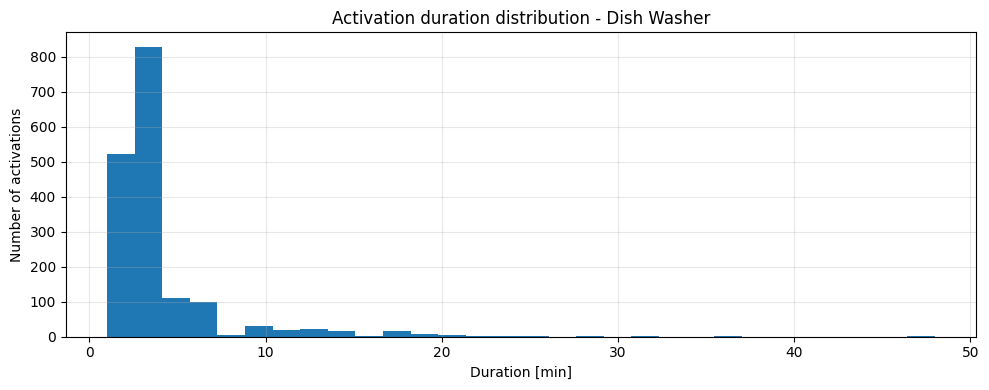

In [22]:
plt.figure(figsize=(10, 4))
plt.hist(activations_df["duration_min"], bins=30)
plt.xlabel("Duration [min]")
plt.ylabel("Number of activations")
plt.title(f"Activation duration distribution - {device_names[device_idx]}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

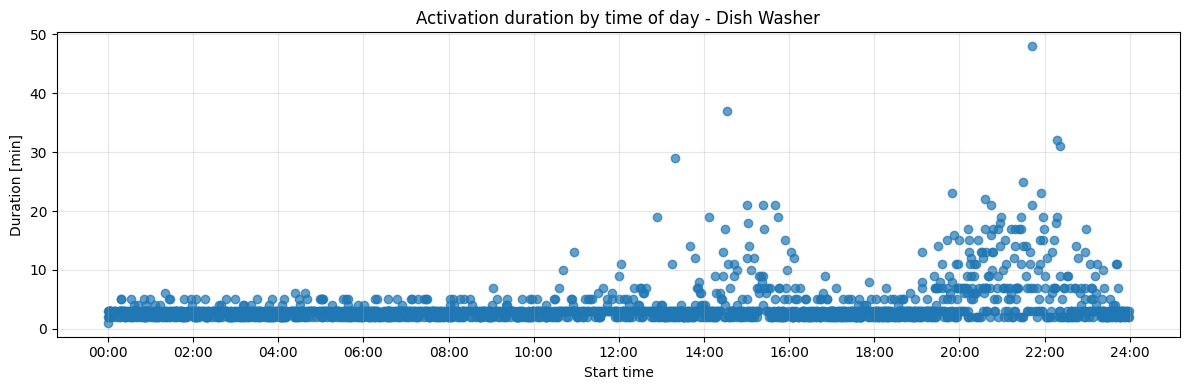

In [23]:
plt.figure(figsize=(12, 4))
plt.scatter(
    activations_df["start_minute_of_day"],
    activations_df["duration_min"],
    alpha=0.7
)

xticks = np.arange(0, 1441, 120)
plt.xticks(
    xticks,
    [f"{int(x//60):02d}:00" for x in xticks]
)

plt.xlabel("Start time")
plt.ylabel("Duration [min]")
plt.title(f"Activation duration by time of day - {device_names[device_idx]}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Clustering Marcelo

In [6]:
directory = '/Users/luismartins/Desktop/Tese/Tese_repository/Data/Postponable Devices'

csv_files = [

    f for f in os.listdir(directory)

    if f.endswith('.csv')

]

dataframes_p_total = {}
activations_dfs = {}

# ---------------------------------------------------------
# 8. Função .main para determinar novas features nas ativações (T2.1 código)
# ---------------------------------------------------------

def clean_var_name(filename):
    name = filename.replace('.csv', '')
    return re.sub(r'[^a-zA-Z0-9_]', '_', name)

for file in csv_files:
    var_name = clean_var_name(file)
    df = pd.read_csv(os.path.join(directory, file), sep=None, engine='python')

    if 'Timestamp' in df.columns:
        df['Timestamp'] = pd.to_datetime(df['Timestamp'])
        df.set_index('Timestamp', inplace=True)

    if 'P_Total' in df.columns:
        series = df['P_Total'].sort_index()
        dataframes_p_total[var_name] = series

        raw_results = detect_activations(series)
        intervals = raw_results['activations']

        act_data = []
        for start, end in intervals:
            if start is None or end is None: continue

            # Extract the actual data slice (includes both index and values)
            mask = series.loc[start:end]
            if len(mask) == 0: continue

            # Metrics calculations
            duration_td = (end - start)
            duration_minutes = duration_td.total_seconds() / 60
            duration_hours = duration_td.total_seconds() / 3600

            avg_power = mask.mean()
            energy_kwh = (avg_power * duration_hours) / 1000
            max_p = mask.max()

            #Novas features T2.1
            act_data.append({
                'start_time': start,
                'end_time': end,
                'duration [min]': round(duration_minutes, 2),
                'total_energy_consumed [kWh]': energy_kwh,
                'avg_power [W]': round(avg_power, 2),
                'max_power [W]': max_p,
                'day_of_week': start.day_name(),
            })

        df_activations = pd.DataFrame(act_data)
        activations_dfs[var_name] = df_activations
        globals()[f"atv_{var_name}"] = df_activations

        print(f"Processed: {file} -> {len(df_activations)} activations found.")
    else:
        print(f"Warning: 'P_Total' not found in {file}")

Using threshold: 4.451
Processed: 04_Dish-Washer.csv -> 2769 activations found.
Using threshold: 1.885
Processed: 09_Glass-Washer.csv -> 793 activations found.


In [5]:
# ---------------------------------------------------------
# 1. Threshold adaptativo (Algoritmo 2 do paper do Ricardo)
# ---------------------------------------------------------
def find_threshold(series, n_classes_small=100, n_classes_large=500):

    max_val = series.max()
    n_classes = n_classes_large if max_val > 1000 else n_classes_small

    hist, bin_edges = np.histogram(series, bins=n_classes)

    # encontrar bin que contém zero
    for i in range(len(bin_edges)-1):
        if bin_edges[i] <= 0 <= bin_edges[i+1]:
            upper_limit = bin_edges[i+1]
            return upper_limit / 2.0

    # fallback (não deve acontecer)
    return series.mean() * 0.1


# ---------------------------------------------------------
# 2. Classificação ON/OFF ponto-a-ponto
# ---------------------------------------------------------
def classify_on_off(series, threshold):

    return (series >= threshold).astype(int)


# ---------------------------------------------------------
# 3. Fusão de ativações separadas por standby curto
# ---------------------------------------------------------
def merge_activations(on_off, timestamps, max_standby_seconds):

    activations = []
    is_on = False
    start = None

    for i in range(1, len(on_off)):
        prev, curr = on_off[i-1], on_off[i]

        # transição OFF -> ON
        if prev == 0 and curr == 1:
            if not is_on:
                start = timestamps[i]
                is_on = True

        # transição ON -> OFF
        if prev == 1 and curr == 0:
            end = timestamps[i]
            is_on = False
            activations.append([start, end])

    # Caso termine ON
    if is_on:
        activations.append([start, timestamps[-1]])

    # -----------------------------------------------------
    # Fusão de ativações separadas por standby curto
    # -----------------------------------------------------
    merged = []
    if not activations:
        return merged

    current_start, current_end = activations[0]

    for i in range(1, len(activations)):
        next_start, next_end = activations[i]

        standby = (next_start - current_end).total_seconds()

        if standby <= max_standby_seconds:
            # fundir
            current_end = next_end
        else:
            merged.append([current_start, current_end])
            current_start, current_end = next_start, next_end

    merged.append([current_start, current_end])
    return merged


# ---------------------------------------------------------
# 4. Implementa o Algoritmo 1 do paper do Ricardo
# ---------------------------------------------------------
def detect_activations(power_series, max_standby_seconds=120):

    # garantir ordenação temporal
    power_series = power_series.sort_index()

    # 1. threshold adaptativo
    threshold = find_threshold(power_series)
    print(f"Using threshold: {threshold}")

    # 2. classificar ON/OFF
    on_off = classify_on_off(power_series, threshold).values
    timestamps = power_series.index.to_numpy()

    # 3. fusão
    activations = merge_activations(on_off, timestamps, max_standby_seconds)

    return {
        "threshold": threshold,
        "activations": activations
    }


# ---------------------------------------------------------
# 5. Nova Função T2.1: Remoção de Outliers (Método IQR)
# ---------------------------------------------------------
def remove_activation_outliers(df, factor=1.5, verbose=True):

    df_clean = df.copy()
    initial_shape = df_clean.shape[0]

    # 1. Outliers para Duração [min]
    Q1_dur = df_clean['duration [min]'].quantile(0.25)
    Q3_dur = df_clean['duration [min]'].quantile(0.75)
    IQR_dur = Q3_dur - Q1_dur
    limit_dur = Q3_dur + (factor * IQR_dur)

    # 2. Outliers para Energia Consumida [kWh]
    Q1_energy = df_clean['total_energy_consumed [kWh]'].quantile(0.25)
    Q3_energy = df_clean['total_energy_consumed [kWh]'].quantile(0.75)
    IQR_energy = Q3_energy - Q1_energy
    limit_energy = Q3_energy + (factor * IQR_energy)

    # Filtrar o DataFrame (mantemos apenas o que está ABAIXO dos limites superiores)
    # Nota: Não filtramos o limite inferior porque durações/energia perto de 0 são normais
    df_clean = df_clean[
        (df_clean['duration [min]'] <= limit_dur) &
        (df_clean['total_energy_consumed [kWh]'] <= limit_energy)
    ]

    if verbose:
        removed = initial_shape - df_clean.shape[0]
        print(f"--- Limpeza de Outliers ---")
        print(f"Limite Superior Duração: {limit_dur:.1f} min")
        print(f"Limite Superior Energia: {limit_energy:.2f} kWh")
        print(f"Ativações removidas: {removed} de {initial_shape} ({removed/initial_shape*100:.1f}%)")
        print(f"---------------------------\n")

    return df_clean




%matplotlib inline

# ---------------------------------------------------------
# 6. Clustering code (adapted from my master Thesis EV4EU)
# ---------------------------------------------------------

#find best number of clusters for k-means
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler
import pandas as pd
import plotly.express as px
import matplotlib as mpl

# User defined color mapping
color_dict = {0: '#540154', 1: '#5e25fc', 2: '#3F5592', 3: '#4F9DDC', 4: '#FD9170', 5: '#1c917a',
              6: '#5bc660', 7: '#A9E73D', 8: '#fc6625', 9:'#fcbf25', 10:'#d1fc25', 11:'#ede695', 12:'#e084d4'}


def find_best_k_means(df):

    df_feat = df.copy()

    # Converter start_time para uma feature numérica
    df_feat['start_seconds'] = df_feat['start_time'].dt.hour * 3600 + \
                               df_feat['start_time'].dt.minute * 60 + \
                               df_feat['start_time'].dt.second

    # Para visualização, converter também para horas decimais
    df_feat['start_hour'] = df_feat['start_seconds'] / 3600

    features = ['duration [min]', 'total_energy_consumed [kWh]']
    X = df_feat[features].values
    
    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    distortions = []
    K = range(2,18+1)
    sillhoute_scores = []
    

    for k in K:
        kmeanModel = KMeans(n_clusters=k)
        kmeanModel.fit(X)
        distortions.append(kmeanModel.inertia_)
        sillhoute_scores.append(silhouette_score(X, kmeanModel.labels_))
        #distortions.append(sum(np.min(cdist(X, kmeanModel.cluster_centers_, 'euclidean'), axis=1)) / X.shape[0])

    return distortions, K, sillhoute_scores



def plot_elbow_method(distortions, K, blue_color_3, sillhoute_scores):

    plt.figure(figsize=(4,3))
    plt.plot(K, distortions, 'x-', color=blue_color_3)
    plt.xlabel('Number of clusters, k')
    plt.ylabel('Inertia')
    #plt.title('The Elbow Method showing the optimal k')
    plt.grid(axis='both', zorder=0)
    plt.gca().spines['bottom'].set_color('#b1b3b5')
    plt.gca().tick_params(axis='both', which='both', length=0)


    plt.show()


    plt.figure(figsize=(4,3))
    plt.scatter(K, sillhoute_scores, color=blue_color_3)
    plt.xlabel('Number of clusters, k')
    plt.ylabel('Silhouette score')
    plt.grid(axis='both', zorder=0)
    plt.gca().spines['bottom'].set_color('#b1b3b5')
    plt.gca().tick_params(axis='both', which='both', length=0)


    plt.show()



# Force static mode for report consistency
%matplotlib inline

def find_best_k_means_features(df, features, k_min=2, k_max=18):
    df_feat = df.copy()

    if 'start_hour' in features and 'start_hour' not in df_feat.columns:
        df_feat['start_hour'] = (
            df_feat['start_time'].dt.hour
            + df_feat['start_time'].dt.minute / 60
            + df_feat['start_time'].dt.second / 3600
        )

    X = df_feat[features].values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    distortions = []
    silhouette_scores = []
    K = range(k_min, k_max + 1)

    for k in K:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_scaled)

        distortions.append(kmeans.inertia_)
        silhouette_scores.append(silhouette_score(X_scaled, labels))

    best_k = list(K)[np.argmax(silhouette_scores)]

    print("Features:", features)
    print(f"Best K: {best_k}")
    print(f"Best silhouette: {max(silhouette_scores):.3f}")

    for k, s in zip(K, silhouette_scores):
        print(f"K={k}: {s:.3f}")

    return distortions, K, silhouette_scores, best_k

def cluster_activations_with_features(df, features, n_clusters=None):
    df_feat = df.copy()

    if 'start_hour' in features and 'start_hour' not in df_feat.columns:
        df_feat['start_hour'] = (
            df_feat['start_time'].dt.hour
            + df_feat['start_time'].dt.minute / 60
            + df_feat['start_time'].dt.second / 3600
        )

    X = df_feat[features].values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    if n_clusters is None:
        _, _, silhouette_scores, best_k = find_best_k_means_features(
            df_feat,
            features
        )
        n_clusters = best_k

    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    df_feat['cluster_feature'] = kmeans.fit_predict(X_scaled)

    print(f"Clustering done with K={n_clusters}")
    print("Features used:", features)

    return df_feat, kmeans, scaler

def plot_3d_clusters(df, cluster_col, elev_=13, azim_=-114):
    fig = plt.figure(figsize=(6, 5.5))
    ax = fig.add_subplot(111, projection='3d')

    for cluster_id in sorted(df[cluster_col].unique()):
        subset = df[df[cluster_col] == cluster_id]
        ax.scatter(subset['duration [min]'],
                   subset['total_energy_consumed [kWh]'],
                   color=color_dict[cluster_id],
                   label=f'{cluster_id}',
                   alpha=0.6, s=30)

    ax.legend(title="Clusters", loc="upper right", bbox_to_anchor=(1.1, 0.84), fontsize=9.5)
    ax.set_ylabel('Duration [min]')
    ax.set_zlabel('Energy [kWh]', )
    ax.set_xlim(0, 24)
    ax.view_init(elev=elev_, azim=azim_)
    plt.tight_layout()
    plt.show()

def plot_2d_duration_energy(df, cluster_col):
    plt.figure(figsize=(8, 6))

    for cluster_id in sorted(df[cluster_col].unique()):
        subset = df[df[cluster_col] == cluster_id]

        plt.scatter(
            subset['duration [min]'],
            subset['total_energy_consumed [kWh]'],
            color=color_dict[cluster_id],
            label=f'{cluster_id}',
            alpha=0.7,
            s=40
        )

    plt.xlabel('Duration [min]')
    plt.ylabel('Energy [kWh]')
    plt.title('Duration vs Energy')
    plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

--- Limpeza de Outliers ---
Limite Superior Duração: 27.4 min
Limite Superior Energia: 1.10 kWh
Ativações removidas: 16 de 2769 (0.6%)
---------------------------

Features: ['duration [min]', 'total_energy_consumed [kWh]']
Best K: 2
Best silhouette: 0.849
K=2: 0.849
K=3: 0.797
K=4: 0.781
K=5: 0.726
K=6: 0.722
K=7: 0.733
K=8: 0.731
K=9: 0.724
K=10: 0.725
K=11: 0.725
K=12: 0.726
K=13: 0.727
K=14: 0.696
K=15: 0.695
K=16: 0.694
K=17: 0.694
K=18: 0.696
Clustering done with K=2
Features used: ['duration [min]', 'total_energy_consumed [kWh]']


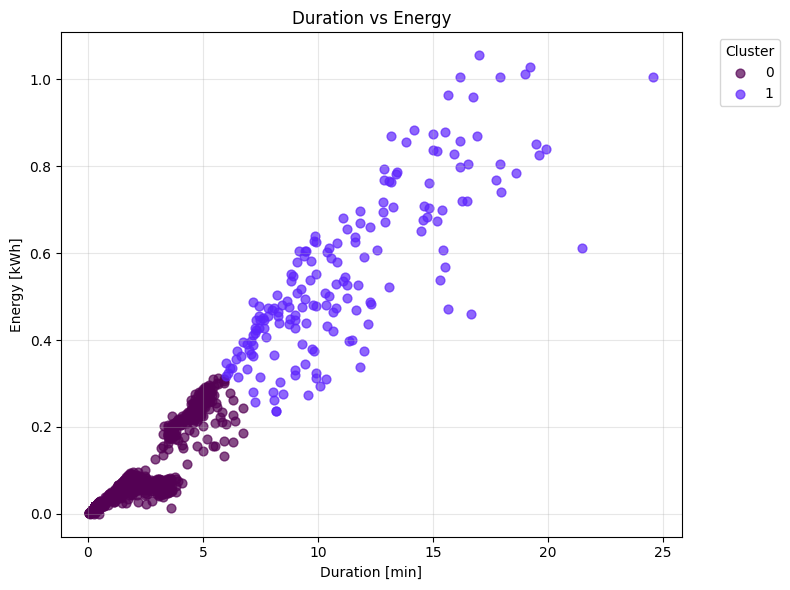

In [7]:
app_name = '04_Dish_Washer'
target_df = activations_dfs[app_name]

# [PASSO NOVO] Remover outliers antes de fazer o clustering --->>>
target_df = remove_activation_outliers(target_df, factor=20)

features = [
    'duration [min]',
    'total_energy_consumed [kWh]',]

df_clustered, model_power, scaler_power = cluster_activations_with_features(
    target_df,
    features,
    n_clusters=None
)

plot_2d_duration_energy(df_clustered, 'cluster_feature')

In [8]:
target_df[
    [
        'duration [min]',
        'total_energy_consumed [kWh]',
        'avg_power [W]',
        'max_power [W]'
    ]
].corr()

,duration [min],total_energy_consumed [kWh],avg_power [W],max_power [W]
duration [min],1.000000,0.967916,0.127292,0.181293
total_energy_consumed [kWh],0.967916,1.000000,0.286326,0.194630
avg_power [W],0.127292,0.286326,1.000000,0.237581
max_power [W],0.181293,0.194630,0.237581,1.000000


In [9]:
summary = (
    df_clustered
    .groupby('cluster_feature')
    .agg(
        n_activations=('cluster_feature', 'size'),
        mean_duration_min=('duration [min]', 'mean'),
        std_duration_min=('duration [min]', 'std'),
        mean_energy_kwh=('total_energy_consumed [kWh]', 'mean'),
        std_energy_kwh=('total_energy_consumed [kWh]', 'std'),
        mean_avg_power=('avg_power [W]', 'mean'),
        mean_max_power=('max_power [W]', 'mean')
    )
    .round(2)
)

print(summary)

                 n_activations  mean_duration_min  std_duration_min  \
cluster_feature                                                       
0                         2575               1.15              1.28   
1                          178              11.17              3.67   

                 mean_energy_kwh  std_energy_kwh  mean_avg_power  \
cluster_feature                                                    
0                           0.05            0.06         2536.99   
1                           0.55            0.19         3009.03   

                 mean_max_power  
cluster_feature                  
0                       3780.94  
1                       4296.94  


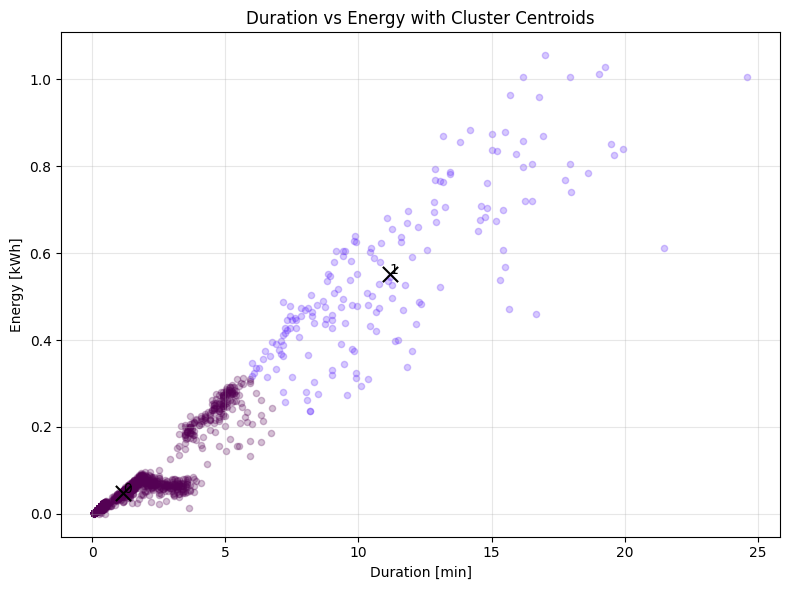

In [10]:
def plot_2d_duration_energy_centroids(df, cluster_col):
    plt.figure(figsize=(8,6))

    for cluster_id in sorted(df[cluster_col].unique()):
        subset = df[df[cluster_col] == cluster_id]

        plt.scatter(
            subset['duration [min]'],
            subset['total_energy_consumed [kWh]'],
            color=color_dict[cluster_id],
            alpha=0.25,
            s=20
        )

        cx = subset['duration [min]'].mean()
        cy = subset['total_energy_consumed [kWh]'].mean()

        plt.scatter(
            cx, cy,
            color='black',
            marker='x',
            s=120
        )

        plt.text(
            cx,
            cy,
            str(cluster_id),
            fontsize=10
        )

    plt.xlabel('Duration [min]')
    plt.ylabel('Energy [kWh]')
    plt.title('Duration vs Energy with Cluster Centroids')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    
plot_2d_duration_energy_centroids(df_clustered, 'cluster_feature')

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_cluster_sequence_24h(df, cluster_col='cluster_feature', date=None):
    data = df.copy()
    data['start_time'] = pd.to_datetime(data['start_time'])
    data['end_time'] = pd.to_datetime(data['end_time'])

    if date is not None:
        date = pd.to_datetime(date).date()
        data = data[data['start_time'].dt.date == date]

    data = data.sort_values('start_time')

    data['start_hour'] = (
        data['start_time'].dt.hour
        + data['start_time'].dt.minute / 60
        + data['start_time'].dt.second / 3600
    )

    data['duration_hours'] = data['duration [min]'] / 60

    plt.figure(figsize=(14, 4))

    for cluster_id in sorted(data[cluster_col].unique()):
        subset = data[data[cluster_col] == cluster_id]

        plt.scatter(
            subset['start_hour'],
            subset[cluster_col],
            s=60,
            alpha=0.8,
            label=f'Cluster {cluster_id}'
        )

        # Optional: draw horizontal duration bars
        for _, row in subset.iterrows():
            plt.hlines(
                y=row[cluster_col],
                xmin=row['start_hour'],
                xmax=row['start_hour'] + row['duration_hours'],
                alpha=0.5,
                linewidth=3
            )

    plt.xlabel('Hour of day')
    plt.ylabel('Cluster')
    plt.title('Dishwasher activation clusters across 24h')
    plt.xticks(range(0, 25, 1))
    plt.yticks(sorted(data[cluster_col].unique()))
    plt.grid(alpha=0.3)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

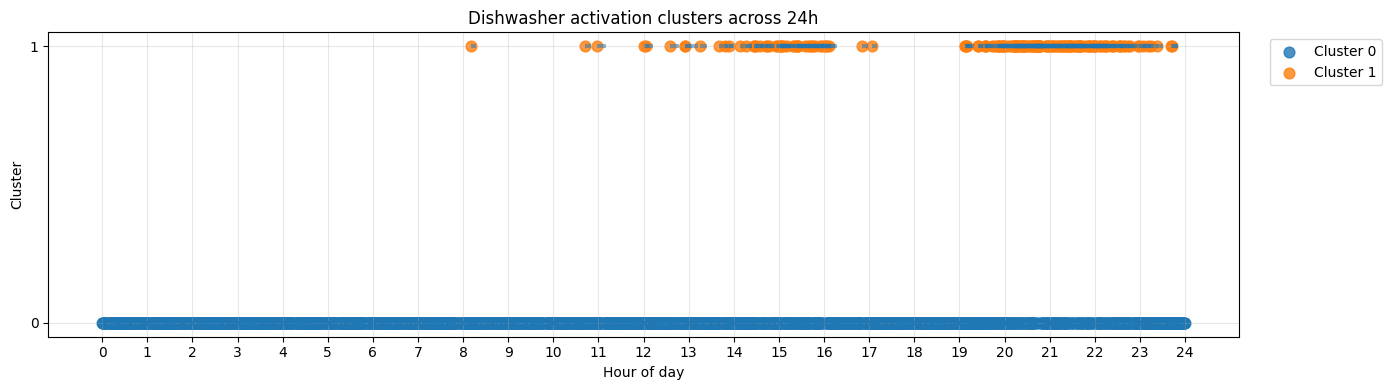

In [12]:
plot_cluster_sequence_24h(df_clustered)

Número de dias: 27

Primeiros 20 dias:
2019-02-06
2019-02-07
2019-02-08
2019-02-09
2019-02-10
2019-02-11
2019-02-12
2019-02-13
2019-02-14
2019-02-15
2019-02-16
2019-02-17
2019-02-18
2019-02-19
2019-02-20
2019-02-21
2019-02-22
2019-02-23
2019-02-24
2019-02-25


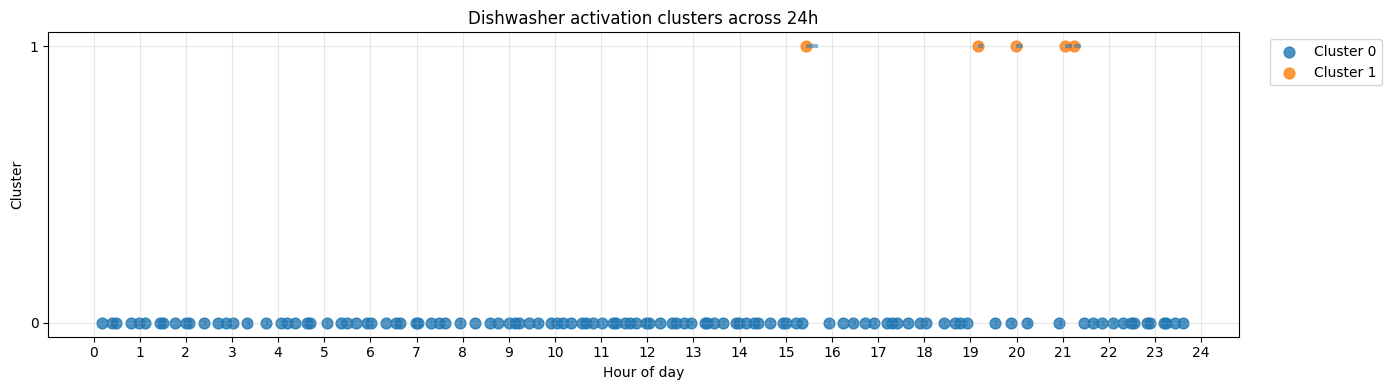

In [15]:
df_clustered['start_time'] = pd.to_datetime(df_clustered['start_time'])

available_days = sorted(
    df_clustered['start_time'].dt.date.unique()
)

print("Número de dias:", len(available_days))
print("\nPrimeiros 20 dias:")
for d in available_days[:20]:
    print(d)
    
plot_cluster_sequence_24h(
    df_clustered,
    date=str(available_days[4])
)

Features: ['duration [min]', 'total_energy_consumed [kWh]', 'max_power [W]']
Best K: 4
Best silhouette: 0.787
K=2: 0.723
K=3: 0.740
K=4: 0.787
K=5: 0.782
K=6: 0.745
K=7: 0.749
K=8: 0.745
K=9: 0.741
K=10: 0.729
K=11: 0.555
K=12: 0.717
K=13: 0.541
K=14: 0.541
K=15: 0.404
K=16: 0.540
K=17: 0.525
K=18: 0.526
Clustering done with K=4
Features used: ['duration [min]', 'total_energy_consumed [kWh]', 'max_power [W]']


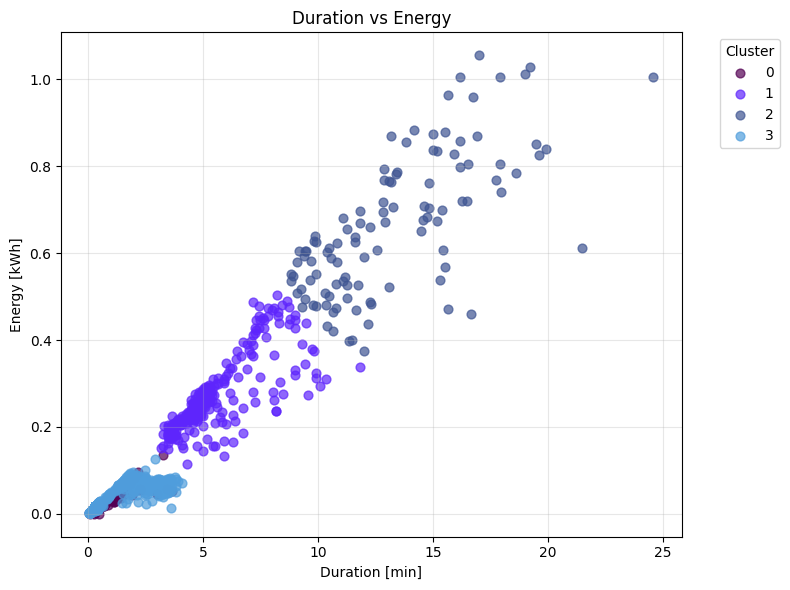

In [ ]:
features = [
    'duration [min]',
    'total_energy_consumed [kWh]',
    'max_power [W]']

df_clustered, model_power, scaler_power = cluster_activations_with_features(
    target_df,
    features,
    n_clusters=None
)

plot_2d_duration_energy(df_clustered, 'cluster_feature')